[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LucaswasTaken/Openhardware-hpc/blob/master/notebooks/Aula2_GPU.ipynb)

# Aula 2 — GPU na prática
### Computação de Alto Desempenho em Python para Engenharia Civil

**Ao final desta aula você vai saber:**
1. quando uma GPU ajuda — e quando atrapalha;
2. por que **onde o dado mora** (RAM ou memória da GPU) decide quase tudo;
3. levar um código NumPy para a GPU com **CuPy**, trocando `np` por `cp`;
4. medir certo e comparar CPU × GPU no seu próprio exercício.

| Tempo | Bloco |
|---|---|
| 0:00–0:20 | 1. Por que GPU? Milhares de operários |
| 0:20–0:50 | 2. Dois mundos: a memória do computador e a da GPU |
| 0:50–1:30 | 3. CuPy em 3 passos |
| 1:30–1:45 | ☕ Intervalo |
| 1:45–2:45 | 4. Projeto: laje em incêndio, na CPU e na GPU |
| 2:45–3:15 | 5. O seu exercício na GPU (escada de speedup) |
| 3:15–3:30 | 6. Quando usar GPU, e as outras ferramentas |
| — | Apêndice (opcional): escrever kernels; memória gerenciada |

### Como usar este notebook
- **Antes de tudo (Colab):** menu *Ambiente de execução → Alterar o tipo de ambiente de execução → **T4 GPU** → Salvar*.
- Rode as células **em ordem**, com **Shift + Enter**.
- Células que começam com `%%gpu` só rodam se houver GPU; sem GPU, elas avisam e pulam — o resto funciona.
- Não entendeu uma linha? Use os prompts **💬 Peça à IA** — eles já vêm prontos para colar no ChatGPT, Claude ou Gemini.

**▶ O que esta célula faz:** prepara tudo: importa as bibliotecas, descobre se há GPU e cria duas ferramentas — `cronometro` (mede tempo do jeito certo) e `registrar` (guarda os números da aula).  
**👀 O que observar:** a última linha deve dizer `GPU: True`. Se disser `False` no Colab, volte e escolha a **T4 GPU**.

In [1]:
import json, os, sys, time, platform, pathlib, datetime, warnings
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", message=".*CUDA path could not be detected.*")
warnings.filterwarnings("ignore", message=".*under-utilization due to low occupancy.*")

NO_COLAB = "google.colab" in sys.modules
try:
    import cupy as cp                               # CuPy: o "NumPy da GPU"
    GPU = cp.cuda.runtime.getDeviceCount() > 0
except Exception as erro:                           # sem CuPy ou sem placa NVIDIA
    cp, GPU = None, False
    print("Sem GPU:", erro)

from IPython.core.magic import register_cell_magic
@register_cell_magic
def gpu(linha, celula):
    """%%gpu no topo da célula: roda só se houver GPU."""
    if not GPU:
        print("⏭️  célula de GPU pulada (sem GPU). No Colab: Ambiente de execução → T4 GPU.")
        return
    get_ipython().run_cell(celula)

MAQUINA = "colab" if NO_COLAB else "local"
RESULTADOS = {"maquina": MAQUINA, "python": platform.python_version(), "data": datetime.date.today().isoformat()}

def registrar(chave, **valores):
    """Guarda os números medidos em results/aula2_<maquina>.json (usados nos slides e vídeos)."""
    RESULTADOS[chave] = valores
    pasta = pathlib.Path("results"); pasta.mkdir(exist_ok=True)
    (pasta / f"aula2_{MAQUINA}.json").write_text(json.dumps(RESULTADOS, indent=1, ensure_ascii=False), encoding="utf-8")
    return valores

def sincroniza():
    """Espera a GPU terminar. Sem isso, o relógio para antes da conta acabar."""
    if GPU: cp.cuda.Device().synchronize()

def cronometro(f, *args, repeticoes=5, aquecer=True):
    """Roda 1 vez para aquecer, depois mede várias vezes e devolve o MENOR tempo (em segundos)."""
    if aquecer: f(*args); sincroniza()
    tempos = []
    for _ in range(repeticoes):
        sincroniza(); t = time.perf_counter(); f(*args); sincroniza()
        tempos.append(time.perf_counter() - t)
    return min(tempos)

print(f"Python {platform.python_version()} · {os.cpu_count()} núcleos de CPU · CuPy {cp.__version__ if cp else '—'} · GPU: {GPU}")

Python 3.12.13 · 12 núcleos de CPU · CuPy 14.2.0 · GPU: True


## 1. Por que GPU? Milhares de operários  ·  0:00–0:20
> 🎬 **Vídeo (1 min):** [GPU: milhares de operários](https://lucaswastaken.github.io/Openhardware-hpc/#v07)

Pense numa obra:
- A **CPU** é uma equipe de **8 engenheiros experientes**. Cada um resolve qualquer problema, rápido, com decisões diferentes ("se a viga não passa, aumente a seção").
- A **GPU** é uma equipe de **2 500 operários**. Cada um é mais lento e só sabe fazer uma tarefa simples — mas **todos fazem a mesma tarefa ao mesmo tempo**, cada um no seu pedaço.

| | CPU | GPU |
|---|---|---|
| Quantos núcleos | poucos (2–64), espertos | milhares, simples |
| Brilha em | tarefas diferentes, com muitos `if` | **a mesma conta em milhões de dados** |
| Exemplos de engenharia | montar a malha, decidir o próximo passo | tensões em 1 milhão de pontos, temperatura em cada nó, Monte Carlo |

**A pergunta-chave da aula:** o meu problema tem *muitos dados* recebendo *a mesma conta*? Se sim, a GPU pode ajudar.

**▶ O que esta célula faz:** pergunta à GPU quem ela é: nome, quantos núcleos e quanta memória tem.  
**👀 O que observar:** compare o número de núcleos da GPU com os da CPU (impresso na célula anterior). No Colab, a T4 tem **2 560 núcleos** e **15 GB** de memória própria.

In [2]:
%%gpu
p = cp.cuda.runtime.getDeviceProperties(0)
nome = p["name"].decode() if isinstance(p["name"], bytes) else p["name"]
nucleos_por_sm = {(7, 5): 64, (8, 0): 64}.get((p["major"], p["minor"]), 128)   # depende da geração da placa
nucleos = p["multiProcessorCount"] * nucleos_por_sm
memoria = p["totalGlobalMem"] / 2**30
print(f"GPU: {nome}")
print(f"  {nucleos:,} núcleos  (a CPU tem {os.cpu_count()})")
print(f"  {memoria:.1f} GB de memória PRÓPRIA da GPU")
registrar("gpu", nome=nome, nucleos=nucleos, memoria_gib=memoria, cpu_nucleos=os.cpu_count())

GPU: NVIDIA GeForce MX570 A
  2,048 núcleos  (a CPU tem 12)
  4.0 GB de memória PRÓPRIA da GPU


{'nome': 'NVIDIA GeForce MX570 A',
 'nucleos': 2048,
 'memoria_gib': 3.99957275390625,
 'cpu_nucleos': 12}

## 2. Dois mundos: a memória do computador e a da GPU  ·  0:20–0:50
> 🎬 **Vídeo (1 min):** [Leve os dados uma vez](https://lucaswastaken.github.io/Openhardware-hpc/#v08)

Na maioria dos computadores (e no Colab), a GPU é uma **placa separada**, com a **sua própria memória** (a VRAM). Para a GPU calcular, os dados precisam **viajar**:

```
   RAM (memória do computador)  ──── cabo PCIe ────▶  VRAM (memória da GPU)
        a CPU trabalha aqui           🚚 a viagem          a GPU trabalha aqui
```

É como uma obra cujo material está num **depósito do outro lado da cidade**: os operários são rápidos, mas o caminhão leva tempo. Se cada viagem traz material para só **uma** tarefa curta, os operários passam o dia esperando o caminhão.

Vamos medir: quanto custa a viagem, e quanto custa a conta?

**▶ O que esta célula faz:** cria 50 milhões de números na RAM e mede três coisas: (1) a viagem RAM → GPU, (2) uma conta **leve** na GPU (multiplicar e somar), (3) uma conta **pesada** na GPU (várias funções trigonométricas), e (4) a viagem de volta.  
**👀 O que observar:** a viagem é **muito mais cara** que a conta leve. Só a conta pesada chega perto do custo da viagem.

viagem RAM → GPU:   128.8 ms
    conta leve:    19.3 ms
  conta pesada:   151.1 ms
viagem GPU → RAM:   163.2 ms

A viagem de ida custa 7× a conta leve.


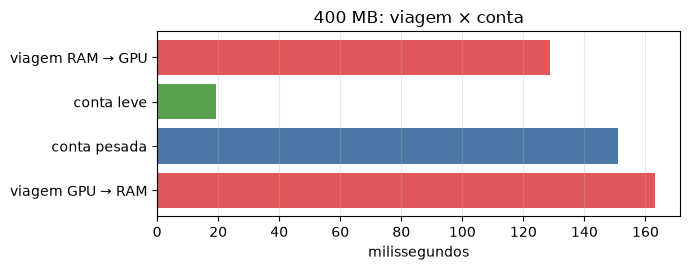

{'mb': 400.0,
 'ida_ms': 128.79860000020926,
 'leve_ms': 19.283599999880607,
 'pesada_ms': 151.05030000017905,
 'volta_ms': 163.15099999997074}

In [3]:
%%gpu
n = 50_000_000
x_ram = np.random.rand(n)                        # 50 milhões de números na RAM (400 MB)
x_gpu = cp.asarray(x_ram)                        # cp.asarray: leva da RAM para a GPU

t_ida   = cronometro(lambda: cp.asarray(x_ram))                          # viagem RAM → GPU
t_leve  = cronometro(lambda: 2.0 * x_gpu + 1.0)                          # conta leve, na GPU
t_pesada = cronometro(lambda: cp.sin(x_gpu) * cp.exp(-x_gpu) + cp.cos(3 * x_gpu) ** 2)  # conta pesada
t_volta = cronometro(lambda: cp.asnumpy(x_gpu))                          # cp.asnumpy: traz de volta

etapas = {"viagem RAM → GPU": t_ida, "conta leve": t_leve, "conta pesada": t_pesada, "viagem GPU → RAM": t_volta}
for k, v in etapas.items():
    print(f"{k:>14}: {v*1e3:7.1f} ms")
print(f"\nA viagem de ida custa {t_ida / t_leve:.0f}× a conta leve.")

plt.figure(figsize=(7, 2.8))
plt.barh(list(etapas), [v * 1e3 for v in etapas.values()], color=["#e15759", "#59a14f", "#4c78a8", "#e15759"])
plt.xlabel("milissegundos"); plt.gca().invert_yaxis(); plt.title("400 MB: viagem × conta"); plt.grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()
registrar("copia_calculo", mb=n * 8 / 1e6, ida_ms=t_ida*1e3, leve_ms=t_leve*1e3, pesada_ms=t_pesada*1e3, volta_ms=t_volta*1e3)

**A regra de ouro da GPU: leve os dados uma vez.** Copie para a GPU no começo, faça **todas** as contas lá, e traga de volta só o resultado final (de preferência pequeno: um número, um mapa).

### E se não houver viagem? Memória unificada
> 🎬 **Vídeo (2 min):** [CPU e GPU: dois mundos ou um só?](https://lucaswastaken.github.io/Openhardware-hpc/#v08b)

O hardware está mudando. Em algumas máquinas novas, **CPU e GPU usam a mesma memória** — o depósito fica *dentro* da obra:

| Tipo de máquina | Exemplos | Há viagem? |
|---|---|---|
| **GPU separada** (placa) | Colab (T4), placas GeForce/RTX, a maioria dos clusters | sim, pelo cabo PCIe |
| **Memória unificada** | Apple M1–M5 (MacBooks), NVIDIA Grace Hopper e DGX Spark, AMD MI300A (supercomputador El Capitan) | não, ou quase nada |

**O que muda:** acaba o custo da viagem, e o código fica mais simples.
**O que NÃO muda:** a GPU continua sendo milhares de operários fazendo **a mesma conta** — continua precisando de **muitos dados** e de **memória rápida**. Memória unificada não transforma um problema sequencial em paralelo.

> No Colab você está numa máquina com **GPU separada**: a regra de ouro vale. (O apêndice B mostra a "memória gerenciada", que finge ser unificada numa placa separada.)

**🧠 Teste rápido**
1. Você precisa somar dois vetores **uma vez** e eles estão na RAM. Vale a pena usar a GPU?
2. E se você for fazer 10 000 passos de simulação com esses vetores?

## 3. CuPy em 3 passos  ·  0:50–1:30
> 🎬 **Vídeo (1 min):** [CuPy em 3 passos](https://lucaswastaken.github.io/Openhardware-hpc/#v09)

O **CuPy** copia o jeito do NumPy. Se você sabe escrever `np.sqrt(x)`, já sabe escrever `cp.sqrt(x)` — e a conta roda na GPU.

| Passo | O que fazer | Em código |
|---|---|---|
| **1. Leve** | mande os dados para a GPU, uma vez | `x = cp.asarray(x_ram)` |
| **2. Calcule** | troque `np` por `cp` | `cp.sqrt(...)`, `cp.sum(...)`, `A @ B` |
| **3. Traga** | traga de volta só o resultado | `cp.asnumpy(y)` ou `float(total)` |

E **para medir** (o `cronometro` já faz isso): **aqueça** (a 1ª chamada é lenta) e **sincronize** (espere a GPU terminar).

### 3.1 Exemplo: tensão de von Mises em 20 milhões de pontos
Num modelo de elementos finitos, cada ponto de integração tem $\sigma_x$, $\sigma_y$ e $\tau_{xy}$. A tensão equivalente de von Mises é $\sqrt{\sigma_x^2 - \sigma_x\sigma_y + \sigma_y^2 + 3\tau_{xy}^2}$.

O truque: `xp = cp.get_array_module(sx)` devolve `np` se os dados estão na RAM e `cp` se estão na GPU. Assim **a mesma função** roda nos dois.

**▶ O que esta célula faz:** define **uma** função de von Mises e roda com dados na RAM (NumPy, CPU) e com dados na GPU (CuPy). Confere que os resultados batem.  
**👀 O que observar:** o resultado é o mesmo (✓) e a GPU é muitas vezes mais rápida — **porque os dados já estão lá**.

In [4]:
%%gpu
def von_mises(sx, sy, txy):
    xp = cp.get_array_module(sx)                 # np se os dados estão na RAM, cp se estão na GPU
    return xp.sqrt(sx**2 - sx*sy + sy**2 + 3*txy**2)

n = 20_000_000
rng = np.random.default_rng(1)
sx, sy, txy = (rng.normal(0, 100, n) for _ in range(3))      # tensões em MPa, na RAM
sx_g, sy_g, txy_g = cp.asarray(sx), cp.asarray(sy), cp.asarray(txy)   # passo 1: leve

t_cpu = cronometro(von_mises, sx, sy, txy, repeticoes=3)
t_gpu = cronometro(von_mises, sx_g, sy_g, txy_g)             # passo 2: a MESMA função, na GPU
vm = cp.asnumpy(von_mises(sx_g, sy_g, txy_g))                # passo 3: traga
assert np.allclose(vm, von_mises(sx, sy, txy))               # confere com a CPU
print(f"NumPy (CPU): {t_cpu*1e3:.0f} ms   CuPy (GPU): {t_gpu*1e3:.1f} ms   →  {t_cpu/t_gpu:.0f}× mais rápido  ✓ resultados iguais")
print(f"Pontos acima de 250 MPa: {(vm > 250).mean():.1%}")
registrar("von_mises", n=n, cpu_ms=t_cpu*1e3, gpu_ms=t_gpu*1e3)

NumPy (CPU): 805 ms   CuPy (GPU): 47.8 ms   →  17× mais rápido  ✓ resultados iguais
Pontos acima de 250 MPa: 27.6%


{'n': 20000000, 'cpu_ms': 805.4632000000765, 'gpu_ms': 47.77709999984836}

💬 **Peça à IA:** *"Explique linha por linha esta função de von Mises com `cp.get_array_module`. O que acontece se eu passar um array NumPy? E um CuPy?"*

### 3.2 O erro mais comum: esquecer de sincronizar
A CPU **pede** a conta à GPU e segue em frente, sem esperar. Se você parar o relógio logo depois de pedir, mede só o tempo do pedido — e acha que a GPU é absurdamente rápida.

**▶ O que esta célula faz:** mede a mesma conta duas vezes: sem esperar a GPU e esperando (sincronizando).  
**👀 O que observar:** o tempo **sem sincronizar** é irrealmente pequeno. Esse é o erro nº 1 em relatórios de GPU — e a IA comete com frequência.

In [5]:
%%gpu
def mede_sem_sincronizar(f):
    f(); sincroniza()                                   # aquece
    t = time.perf_counter(); f(); return time.perf_counter() - t

conta = lambda: von_mises(sx_g, sy_g, txy_g)
print(f"sem sincronizar: {mede_sem_sincronizar(conta)*1e3:6.2f} ms   ← errado: só mediu o pedido")
print(f"sincronizando:   {cronometro(conta)*1e3:6.2f} ms   ← certo")

sem sincronizar:   0.70 ms   ← errado: só mediu o pedido


sincronizando:    48.94 ms   ← certo


### 3.3 Onde a GPU brilha de verdade: multiplicação de matrizes
Somar vetores ou calcular von Mises faz **poucas contas por número** lido. Multiplicar matrizes faz **muitas** (cada número é usado $n$ vezes) — é o melhor cenário para os 2 500 operários.

E um detalhe importante para engenheiros: GPUs comuns (como a T4 e as GeForce) são **muito mais rápidas em `float32`** (precisão simples, ~7 dígitos) do que em `float64` (precisão dupla, ~16 dígitos, o padrão do NumPy).

**▶ O que esta célula faz:** multiplica duas matrizes 4096 × 4096 na CPU e na GPU, em `float64` e em `float32`.  
**👀 O que observar:** na GPU, `float32` é **muitas vezes** mais rápido que `float64`. Para análise estrutural, confira se 7 dígitos bastam antes de trocar.

In [6]:
%%gpu
n = 4096
A = np.random.rand(n, n)
t_cpu = cronometro(lambda: A @ A, repeticoes=2)
linhas = {"CPU float64": t_cpu}
for tipo in (cp.float64, cp.float32):
    Ag = cp.asarray(A, dtype=tipo)
    linhas[f"GPU {np.dtype(tipo).name}"] = cronometro(lambda: Ag @ Ag, repeticoes=3)
for k, t in linhas.items():
    print(f"{k:>12}: {t:7.3f} s   {2*n**3/t/1e9:7.0f} GFLOP/s (bilhões de contas por segundo)")
registrar("matmul", n=n, tempos_s=linhas)

 CPU float64:   0.918 s       150 GFLOP/s (bilhões de contas por segundo)
 GPU float64:   4.038 s        34 GFLOP/s (bilhões de contas por segundo)
 GPU float32:   0.086 s      1598 GFLOP/s (bilhões de contas por segundo)


{'n': 4096,
 'tempos_s': {'CPU float64': 0.9179306000000906,
  'GPU float64': 4.038455800000065,
  'GPU float32': 0.08602189999987786}}

💬 **Peça à IA:** *"Por que a multiplicação de matrizes ganha muito mais com GPU do que a soma de vetores? Explique com a ideia de 'contas por byte' para um engenheiro civil."*

**🧠 Teste rápido**
1. Quais são os 3 passos do CuPy?
2. Um colega diz que a GPU fez a conta em 0,01 ms. Qual a primeira pergunta que você faz?

---
## ☕ Intervalo · 1:30–1:45

## 4. Projeto: laje em incêndio, na CPU e na GPU  ·  1:45–2:45
> 🎬 **Vídeo (1 min):** [Laje em incêndio: CPU × GPU](https://lucaswastaken.github.io/Openhardware-hpc/#v10)

**O problema:** uma laje de concreto (vista em corte, 20 cm × 20 cm) tem a **face de baixo exposta a um incêndio** (600 °C); as outras faces ficam a 20 °C. Como o calor entra na laje ao longo do tempo? A que profundidade chega 500 °C — onde está a armadura?

**Como calcular:** dividimos o corte numa malha de pontos. A cada passo de tempo, **cada ponto fica um pouco mais parecido com a média dos 4 vizinhos**:

```
            cima
   esquerda  [T]  direita        T_novo = T + 0,24 × (cima + baixo + esquerda + direita − 4·T)
            baixo
```

Milhões de pontos, **todos com a mesma conta**, a cada passo, e milhares de passos com os dados **parados na GPU**. É o cenário perfeito.

**▶ O que esta célula faz:** define a laje e três versões da simulação: Python puro (lento, para conferir), **uma função NumPy/CuPy** (o mesmo código roda na CPU e na GPU) e Numba (a CPU com todos os núcleos, como na Aula 1). Confere que todas dão o mesmo resultado.  
**👀 O que observar:** as três linhas de ✓. Repare que `simula` não sabe se está na CPU ou na GPU: quem decide é **onde está o array** `T`.

In [7]:
from numba import njit, prange

R = 0.24                                         # "quanto" cada ponto puxa dos vizinhos por passo (estável se ≤ 0,25)

def laje_inicial(n, xp=np):
    """Malha n × n a 20 °C, com a face de baixo a 600 °C. xp=np → na RAM; xp=cp → na GPU."""
    T = xp.full((n, n), 20.0, dtype=xp.float32)
    T[-1, :] = 600.0
    return T

def simula_python(T, passos):                    # Python puro: só para conferir (é lentíssimo)
    T = T.tolist(); n = len(T)
    for _ in range(passos):
        N = [linha[:] for linha in T]
        for i in range(1, n - 1):
            for j in range(1, n - 1):
                N[i][j] = T[i][j] + R * (T[i+1][j] + T[i-1][j] + T[i][j+1] + T[i][j-1] - 4 * T[i][j])
        T = N
    return np.array(T, dtype=np.float32)

def simula(T, passos):
    """A MESMA função para CPU e GPU: xp vira np ou cp conforme onde T está."""
    xp = cp.get_array_module(T) if cp else np
    A, B = T, T.copy()
    for _ in range(passos):
        B[1:-1, 1:-1] = A[1:-1, 1:-1] + R * (A[2:, 1:-1] + A[:-2, 1:-1] + A[1:-1, 2:] + A[1:-1, :-2] - 4 * A[1:-1, 1:-1])
        A, B = B, A                              # troca: o novo vira o atual
    return A

@njit(parallel=True, cache=True)
def simula_numba(T, passos):                     # Numba: a mesma conta, em laço, com todos os núcleos da CPU
    A, B = T.copy(), T.copy()
    n = T.shape[0]
    for _ in range(passos):
        for i in prange(1, n - 1):
            for j in range(1, n - 1):
                B[i, j] = A[i, j] + R * (A[i+1, j] + A[i-1, j] + A[i, j+1] + A[i, j-1] - 4 * A[i, j])
        A, B = B, A
    return A

ref = simula_python(laje_inicial(48), 100)
assert np.allclose(simula(laje_inicial(48), 100), ref, atol=1e-3);       print("NumPy confere ✓")
assert np.allclose(simula_numba(laje_inicial(48), 100), ref, atol=1e-3); print("Numba confere ✓")
if GPU:
    assert np.allclose(cp.asnumpy(simula(laje_inicial(48, cp), 100)), ref, atol=1e-3); print("CuPy confere ✓")

NumPy confere ✓


Numba confere ✓
CuPy confere ✓


**▶ O que esta célula faz:** roda 300 passos para malhas cada vez maiores (de 128 × 128 até 2048 × 2048 pontos) com NumPy, Numba e CuPy, e desenha o tempo de cada um. Leva 1–2 minutos.  
**👀 O que observar:** em malhas **pequenas** a GPU não ganha (pouco trabalho para tantos operários). A partir de algum tamanho, ela passa à frente. **Onde as curvas se cruzam?**

malha  128 × 128 : NumPy 0.013 s   Numba 0.004 s   CuPy 0.098 s


malha  256 × 256 : NumPy 0.059 s   Numba 0.007 s   CuPy 0.056 s


malha  512 × 512 : NumPy 0.368 s   Numba 0.018 s   CuPy 0.094 s


malha 1024 × 1024: NumPy 5.357 s   Numba 0.056 s   CuPy 0.328 s


malha 2048 × 2048: Numba 0.417 s   CuPy 1.300 s


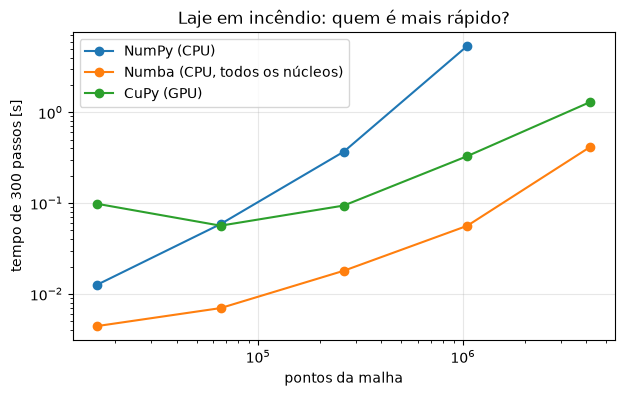

{'passos': 300,
 'tempos': {'NumPy (CPU)': {'128': 0.012631199999987075,
   '256': 0.05869750000010754,
   '512': 0.368484399999943,
   '1024': 5.357156799999984},
  'Numba (CPU, todos os núcleos)': {'128': 0.004423399999950561,
   '256': 0.006974599999921338,
   '512': 0.017981800000143267,
   '1024': 0.056136800000103904,
   '2048': 0.41690399999993133},
  'CuPy (GPU)': {'128': 0.09809169999994083,
   '256': 0.05637869999986833,
   '512': 0.09392640000010033,
   '1024': 0.3282492999999249,
   '2048': 1.2999463000001015}}}

In [8]:
PASSOS = 300
tamanhos = [128, 256, 512, 1024, 2048]
tempos = {"NumPy (CPU)": {}, "Numba (CPU, todos os núcleos)": {}, "CuPy (GPU)": {}}
for n in tamanhos:
    if n <= 1024:                                           # NumPy fica lento demais em 2048
        tempos["NumPy (CPU)"][n] = cronometro(simula, laje_inicial(n), PASSOS, repeticoes=2)
    tempos["Numba (CPU, todos os núcleos)"][n] = cronometro(simula_numba, laje_inicial(n), PASSOS, repeticoes=2)
    if GPU:
        tempos["CuPy (GPU)"][n] = cronometro(simula, laje_inicial(n, cp), PASSOS, repeticoes=3)
    print(f"malha {n:>4} × {n:<4}: " + "   ".join(f"{k.split(' (')[0]} {v[n]:.3f} s" for k, v in tempos.items() if n in v))

fig, ax = plt.subplots(figsize=(7, 4))
for k, v in tempos.items():
    if v: ax.plot([n * n for n in v], list(v.values()), "o-", label=k)
ax.set(xscale="log", yscale="log", xlabel="pontos da malha", ylabel=f"tempo de {PASSOS} passos [s]",
       title="Laje em incêndio: quem é mais rápido?")
ax.legend(); ax.grid(alpha=.3); plt.show()
registrar("calor", passos=PASSOS, tempos={k: {str(n): t for n, t in v.items()} for k, v in tempos.items()})

**Leitura do gráfico:**
- **Malha pequena:** a GPU perde ou empata. Cada passo tem um custo fixo de "dar a ordem" aos operários, e há pouco trabalho para dividir.
- **Malha grande:** a GPU dispara — os dados ficam **parados na GPU** durante os 300 passos (a regra de ouro).
- **Numba na CPU** é um adversário forte: num computador com muitos núcleos e uma GPU pequena, pode até empatar. **Meça no seu hardware antes de concluir.**

💬 **Peça à IA:** *"Neste código da equação do calor, por que a função `simula` funciona com NumPy e CuPy sem mudar nada? O que `cp.get_array_module` faz?"*

**▶ O que esta célula faz:** simula 4 000 passos numa malha 256 × 256 (na GPU se houver; senão na CPU) e desenha o mapa de temperatura com as curvas de 100, 300 e 500 °C.  
**👀 O que observar:** a curva **branca de 500 °C**: até que profundidade ela sobe? Com cobrimento de 2,5 cm, a armadura já passou de 500 °C?

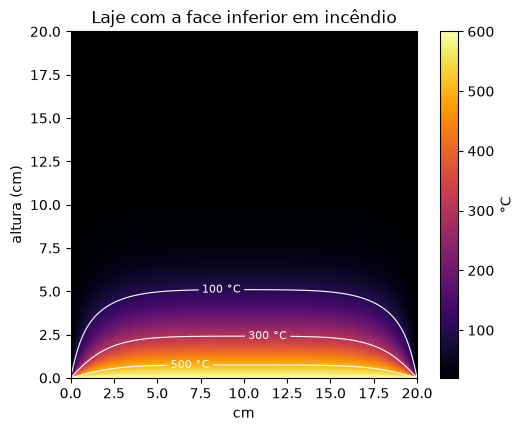

In [9]:
n = 256
T = simula(laje_inicial(n, cp) if GPU else laje_inicial(n), 4000)
T = cp.asnumpy(T) if GPU else T                  # passo 3: traga só o resultado final
plt.figure(figsize=(6, 4.5))
plt.imshow(T, cmap="inferno", extent=[0, 20, 0, 20]); plt.colorbar(label="°C")
cs = plt.contour(T, levels=[100, 300, 500], colors="w", linewidths=.8, extent=[0, 20, 20, 0])
plt.clabel(cs, fmt="%d °C", fontsize=8)
plt.title("Laje com a face inferior em incêndio"); plt.xlabel("cm"); plt.ylabel("altura (cm)"); plt.show()

> **O que este projeto mostrou:** o mesmo código (`simula`) rodou na CPU e na GPU; a GPU ganhou porque os dados **ficaram lá** durante milhares de passos; e para problemas pequenos a CPU basta.

**Para casa (opcional):** troque `R = 0.24` por `R = 0.3` e rode o mapa. O que acontece? (Pesquise "estabilidade de diferenças finitas explícitas".)

---

## 5. O seu exercício na GPU: a escada de speedup  ·  2:45–3:15
> 🎬 **Vídeo (1 min):** [Exemplo da lista na GPU: a escada de speedup](https://lucaswastaken.github.io/Openhardware-hpc/#v13)

Na lista de exercícios ([`exercicios/lista.md`](https://github.com/LucaswasTaken/Openhardware-hpc/blob/master/exercicios/lista.md)) você escolhe **CPU com Numba** ou **GPU com CuPy**. Na CPU, você varia o número de threads. Na GPU não há esse botão — então montamos uma **escada**: o **mesmo problema** resolvido por versões cada vez mais rápidas.

Vamos montar a escada do **exemplo resolvido da lista**: energia de deformação de 20 milhões de molas, $U = \tfrac12\sum k_i\delta_i^2$.

**▶ O que esta célula faz:** resolve o mesmo problema com Python puro (estimado), NumPy, Numba com 1 thread, Numba com todos os núcleos, CuPy com os dados já na GPU, e CuPy contando a viagem RAM → GPU.  
**👀 O que observar:** os dois últimos degraus. Com o dado **já na GPU**, ela compete com a CPU; **contando a viagem**, ela perde para o Numba — porque a conta é leve e é feita uma vez só.

             Python puro:  10.0935 s         1× o Python
                   NumPy:   0.0908 s       111× o Python
         Numba, 1 thread:   0.0379 s       266× o Python
       Numba, 12 threads:   0.0085 s     1,184× o Python
   CuPy (dado já na GPU):   0.0142 s       709× o Python
 CuPy + viagem RAM → GPU:   0.0989 s       102× o Python


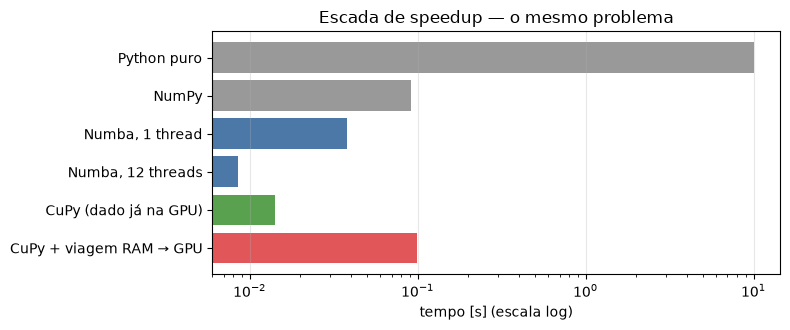

{'n': 20000000,
 'tempos_s': {'Python puro': 10.093524000003526,
  'NumPy': 0.09084669999992911,
  'Numba, 1 thread': 0.03788059999988036,
  'Numba, 12 threads': 0.008525599999984479,
  'CuPy (dado já na GPU)': 0.014235099999950762,
  'CuPy + viagem RAM → GPU': 0.09885329999997339},
 'threads': 12}

In [10]:
from numba import set_num_threads, get_num_threads

def energia_python(k, d):
    u = 0.0
    for i in range(len(k)):
        u += 0.5 * k[i] * d[i] * d[i]
    return u

@njit(parallel=True)
def energia_numba(k, d):
    u = 0.0
    for i in prange(k.size):
        u += 0.5 * k[i] * d[i] * d[i]
    return u

N = 20_000_000
rng = np.random.default_rng(0)
k, d = rng.uniform(1e6, 1e8, N), rng.normal(0, 1e-3, N)     # rigidez [N/m] e deslocamento [m]
ref = 0.5 * np.dot(k, d * d)

P = get_num_threads()
escada = {"Python puro": cronometro(energia_python, k[:500_000], d[:500_000], repeticoes=1, aquecer=False) * N / 500_000,
          "NumPy": cronometro(lambda: 0.5 * np.dot(k, d * d))}
set_num_threads(1); escada["Numba, 1 thread"] = cronometro(energia_numba, k, d)
set_num_threads(P); escada[f"Numba, {P} threads"] = cronometro(energia_numba, k, d)
assert np.isclose(energia_numba(k, d), ref)
if GPU:
    kg, dg = cp.asarray(k), cp.asarray(d)
    energia_cupy = lambda kg, dg: 0.5 * cp.dot(kg, dg * dg)                   # mesmo código do NumPy, com cp
    assert np.isclose(float(energia_cupy(kg, dg)), ref)
    escada["CuPy (dado já na GPU)"] = cronometro(energia_cupy, kg, dg)
    escada["CuPy + viagem RAM → GPU"] = cronometro(lambda: float(energia_cupy(cp.asarray(k), cp.asarray(d))), repeticoes=3)

base = escada["Python puro"]
for nome, t in escada.items():
    print(f"{nome:>24}: {t:8.4f} s   {base / t:7,.0f}× o Python")
cores = ["#999", "#999", "#4c78a8", "#4c78a8", "#59a14f", "#e15759"][:len(escada)]
plt.figure(figsize=(8, 3.4))
plt.barh(list(escada), list(escada.values()), color=cores); plt.xscale("log")
plt.xlabel("tempo [s] (escala log)"); plt.gca().invert_yaxis(); plt.grid(alpha=.3, axis="x")
plt.title("Escada de speedup — o mesmo problema"); plt.tight_layout(); plt.show()
registrar("escada", n=N, tempos_s=escada, threads=P)

**Para fazer o seu exercício:**
1. Abra o [modelo de relatório](https://colab.research.google.com/github/LucaswasTaken/Openhardware-hpc/blob/master/exercicios/modelo_relatorio.ipynb) — ele já tem esta escada pronta (seção 5).
2. Troque as funções marcadas com ✏️ pelas do seu exercício.
3. Rode tudo e escreva a análise.

### Usando IA sem se perder
> 🎬 **Vídeo (1 min):** [Usando IA sem se perder](https://lucaswastaken.github.io/Openhardware-hpc/#v14)

Um prompt que funciona bem:
> *"Tenho esta função em Python [cole a função serial do exercício]. Reescreva com CuPy, mantendo os dados na GPU. Mostre como medir o tempo (aquecer e sincronizar) e como conferir o resultado com a versão original."*

**Antes de acreditar na IA, confira sempre:**
1. ✅ O resultado bate com a função serial (`assert np.isclose(...)`).
2. ✅ Houve aquecimento antes de medir.
3. ✅ Houve sincronização (`cp.cuda.Device().synchronize()`) antes de parar o relógio.
4. ✅ Você sabe dizer se a viagem RAM → GPU está ou não dentro do tempo medido.

## 6. Quando usar GPU? E as outras ferramentas  ·  3:15–3:30

**Checklist — responda antes de levar um problema para a GPU:**
1. **Muitos dados, mesma conta?** Milhões de pontos, elementos, amostras → ✅. Poucos dados ou lógica diferente para cada item → CPU.
2. **Os dados podem ficar na GPU?** Muitos passos com os mesmos dados → ✅. Uma conta só, com dados na RAM → a viagem come o ganho.
3. **Muita conta por número?** (matrizes, simulações, Monte Carlo) → a GPU dispara. Pouca conta (somar, comparar) → ganho pequeno.
4. **`float32` basta?** Em GPUs comuns é muito mais rápido. Confira a precisão.
5. **Mediu direito?** Aquecer, sincronizar, separar a viagem, repetir.

### Outras ferramentas de GPU em Python (para conhecer)
O CuPy resolve a maior parte dos problemas de engenharia. Se um dia precisar de mais:

| Ferramenta | Quando usar | Dificuldade |
|---|---|---|
| **CuPy** ⭐ | trocar `np` por `cp`: arrays, álgebra linear, FFT | fácil |
| Numba-CUDA | escrever sua própria função que cada operário executa (*kernel*) — ver apêndice A | média |
| PyTorch / JAX | redes neurais, otimização, derivadas automáticas; também servem para arrays | média |
| RAPIDS (cuDF) | tabelas grandes (como pandas) na GPU | fácil |
| Apple MLX | Macs com chip M (memória unificada) | média |

### Exercícios
Escolha **um** exercício de [`exercicios/lista.md`](../exercicios/lista.md) e um caminho (CPU/Numba ou GPU/CuPy). Use o [modelo de relatório](../exercicios/modelo_relatorio.ipynb) e, para instalar no seu computador, o [guia de instalação](../exercicios/INSTALACAO.md).
> 🎬 **Vídeo (1 min):** [Como fazer o relatório](https://lucaswastaken.github.io/Openhardware-hpc/#v11)

---
# Apêndice (opcional) — para quem quiser ir além

## A. Escrevendo um kernel com Numba-CUDA
O CuPy esconde os operários. Com **Numba-CUDA**, você escreve a função que **cada operário** executa (um *kernel*). Os operários (*threads*) são organizados em **blocos**, e os blocos formam a **grade**. Cada thread descobre "qual é o meu pedaço" com `cuda.grid(1)`.

Exemplo: estimar π por Monte Carlo (a mesma ideia da probabilidade de falha) — cada thread sorteia 2 000 pontos com o seu próprio gerador aleatório e conta quantos caem dentro do círculo.

**▶ O que esta célula faz:** instala o Numba-CUDA (no Colab), escreve um kernel em que cada thread sorteia pontos, e compara com a versão CuPy.  
**👀 O que observar:** quantas threads foram lançadas (muito mais que os núcleos!) e o valor de π.

In [11]:
%%gpu
if NO_COLAB:
    %pip install -q "numba-cuda[cu12]"
from numba import cuda
from numba.cuda.random import create_xoroshiro128p_states, xoroshiro128p_uniform_float32

@cuda.jit
def conta_no_circulo(estados, amostras, saida):
    i = cuda.grid(1)                       # "eu sou a thread número i"
    if i < saida.size:                     # a última grade pode ter threads sobrando
        dentro = 0
        for _ in range(amostras):
            x = xoroshiro128p_uniform_float32(estados, i)
            y = xoroshiro128p_uniform_float32(estados, i)
            if x * x + y * y <= 1.0:
                dentro += 1
        saida[i] = dentro

THREADS_POR_BLOCO = 256
BLOCOS = 32 * cp.cuda.runtime.getDeviceProperties(0)["multiProcessorCount"]
n_threads = THREADS_POR_BLOCO * BLOCOS
estados = create_xoroshiro128p_states(n_threads, seed=42)
saida = cuda.device_array(n_threads, dtype=np.int32)
AMOSTRAS = 2000

def pi_numba():
    conta_no_circulo[BLOCOS, THREADS_POR_BLOCO](estados, AMOSTRAS, saida)
    return 4 * saida.copy_to_host().sum() / (n_threads * AMOSTRAS)

t = cronometro(pi_numba, repeticoes=3)
print(f"{BLOCOS} blocos × {THREADS_POR_BLOCO} threads = {n_threads:,} threads; {n_threads*AMOSTRAS/1e9:.2f} bilhões de pontos")
print(f"π ≈ {pi_numba():.6f} em {t*1e3:.0f} ms")
registrar("pi_monte_carlo", amostras=n_threads * AMOSTRAS, numba_ms=t * 1e3)

512 blocos × 256 threads = 131,072 threads; 0.26 bilhões de pontos
π ≈ 3.141555 em 87 ms


{'amostras': 262144000, 'numba_ms': 86.87000000008993}

## B. Memória gerenciada: fingindo memória unificada numa placa separada
O CUDA oferece **memória gerenciada**: um único array, válido na CPU e na GPU, sem `cp.asarray`. Parece memória unificada — mas numa placa separada é **ilusão de software**: por baixo, os dados **viajam** pelo PCIe quando um lado precisa deles.

**▶ O que esta célula faz:** cria um array de memória gerenciada e mede: o 1º uso na GPU (os dados viajam), o 2º uso (já estão lá), e o que acontece quando a CPU mexe no array de novo.  
**👀 O que observar:** o 1º kernel é lento (viagem escondida), o 2º é rápido, e depois que a CPU toca nos dados, a viagem volta.

In [12]:
%%gpu
from numba import cuda

@cuda.jit
def escala(x, a):
    i = cuda.grid(1)
    if i < x.size:
        x[i] = a * x[i] + 1.0

def mede(f):
    cuda.synchronize(); t = time.perf_counter(); f(); cuda.synchronize()
    return (time.perf_counter() - t) * 1e3

SOB_DEMANDA = bool(cp.cuda.Device(0).attributes.get("ConcurrentManagedAccess", 0))
if not SOB_DEMANDA:   # Windows e GPUs antigas: a memória gerenciada é limitada (e pode travar) — rode no Colab
    print("Esta máquina não migra dados sob demanda (comum no Windows). Rode este apêndice no Colab.")
else:
    N = 1 << 25                                  # 32 milhões de floats (128 MB)
    BLOCOS_M = (N + 255) // 256
    m = cuda.managed_array(N, np.float32)       # memória gerenciada: o MESMO array na CPU e na GPU
    m[:] = 1.0                                  # a CPU escreve → os dados estão na RAM
    escala[BLOCOS_M, 256](cuda.device_array(256, np.float32), 1.0)    # aquece o kernel
    ger = {"1º kernel (dados viajam)": mede(lambda: escala[BLOCOS_M, 256](m, 2.0)),
           "2º kernel (já na GPU)": mede(lambda: escala[BLOCOS_M, 256](m, 2.0))}
    t = time.perf_counter(); m[::4096] += 1; cuda.synchronize(); ger["CPU mexe no array"] = (time.perf_counter() - t) * 1e3
    ger["kernel depois (viajam de novo)"] = mede(lambda: escala[BLOCOS_M, 256](m, 2.0))
    for k, v in ger.items(): print(f"  {k:<32} {v:8.1f} ms")
    registrar("memoria_gerenciada", mib=N * 4 / 2**20, ms=ger)

Esta máquina não migra dados sob demanda (comum no Windows). Rode este apêndice no Colab.


**Conclusão do apêndice B:** a *interface* já é unificada em quase todo lugar; a *física* (uma memória só) existe em parte do hardware (Apple M, Grace Hopper, MI300A). Numa placa separada, programe pensando em **onde o dado mora**.